# Interpretabilidad con Grad-CAM

Grad-CAM explica al modelo, no a la mariposa: muestra qué regiones movieron la predicción, no qué rasgos distinguen a la especie. Como `auditoria.csv` guarda la caja de detección de cada imagen, se puede medir qué fracción de la activación cae sobre el ejemplar, y la comparación no es contra cero sino contra el área de la caja: la mariposa ocupa ~51 % del recorte, así que una atención repartida al azar daría ~0.51 y solo el exceso es evidencia.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

FIGURAS = ROOT / "outputs" / "gradcam"
FIGURAS.mkdir(parents=True, exist_ok=True)

Raíz del proyecto: /Users/cristiansandoval/Universidad/Semillero/ButterflyModeling


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from scripts import corpus
from scripts import modelRegistry as registro
from scripts.architectures import capaFeatures, preprocessFn
from scripts.gradcam import (areaCaja, cajaEnRecorte, computeGradcam,
                             fraccionDentro, overlayHeatmap)
from scripts.vizStyle import INK_MUTED, SERIE_1, SERIE_2, applyStyle, limpiarEje

MUESTRA = 150       # imágenes de test para la parte cuantitativa
SEMILLA = 42

corpus.materializar()
clases = corpus.classNames()

auditoria = pd.read_csv(corpus.repoDataset() / "auditoria.csv")
auditoria = auditoria[(auditoria.veredicto == "aceptada") & (auditoria.split == "test")]
print(f"{len(auditoria)} imágenes de test con caja de detección")

5057 imágenes de test con caja de detección


## 1 · Los dos modelos a comparar

El desplegado es el que ven los usuarios, así que sus explicaciones son las que importan; el docente sirve de referencia de lo que logra un modelo sin restricción de tamaño.

In [3]:
MODELOS = {}
for rol, archivo in (("desplegado", "desplegado.json"), ("docente", "teacher.json")):
    info = registro.readJson(registro.OUTPUTS_DIR / archivo)
    if info is None:
        print(f"Falta outputs/{archivo}")
        continue
    MODELOS[rol] = {
        "arquitectura": info["architecture"],
        "modelo": registro.modeloInferencia(info["run_id"]),
        "preprocess": preprocessFn(info["architecture"]),
        "f1": info["test_macro_f1"],
    }

pd.DataFrame([{
    "rol": rol, "arquitectura": m["arquitectura"],
    "macro_f1": round(m["f1"], 4),
    "resolucion_mapa": tuple(capaFeatures(m["modelo"]).shape[1:3]),
} for rol, m in MODELOS.items()])

/opt/miniconda3/envs/semillero/lib/python3.12/site-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


,rol,arquitectura,macro_f1,resolucion_mapa
0,desplegado,mobilenet_v3_small,0.9107,"(14, 14)"
1,docente,efficientnet_b0,0.9431,"(14, 14)"


## 2 · Panel cualitativo

Para cada especie se toma la predicción correcta más confiada del modelo desplegado, y se muestra su mapa junto al del docente sobre la misma imagen.

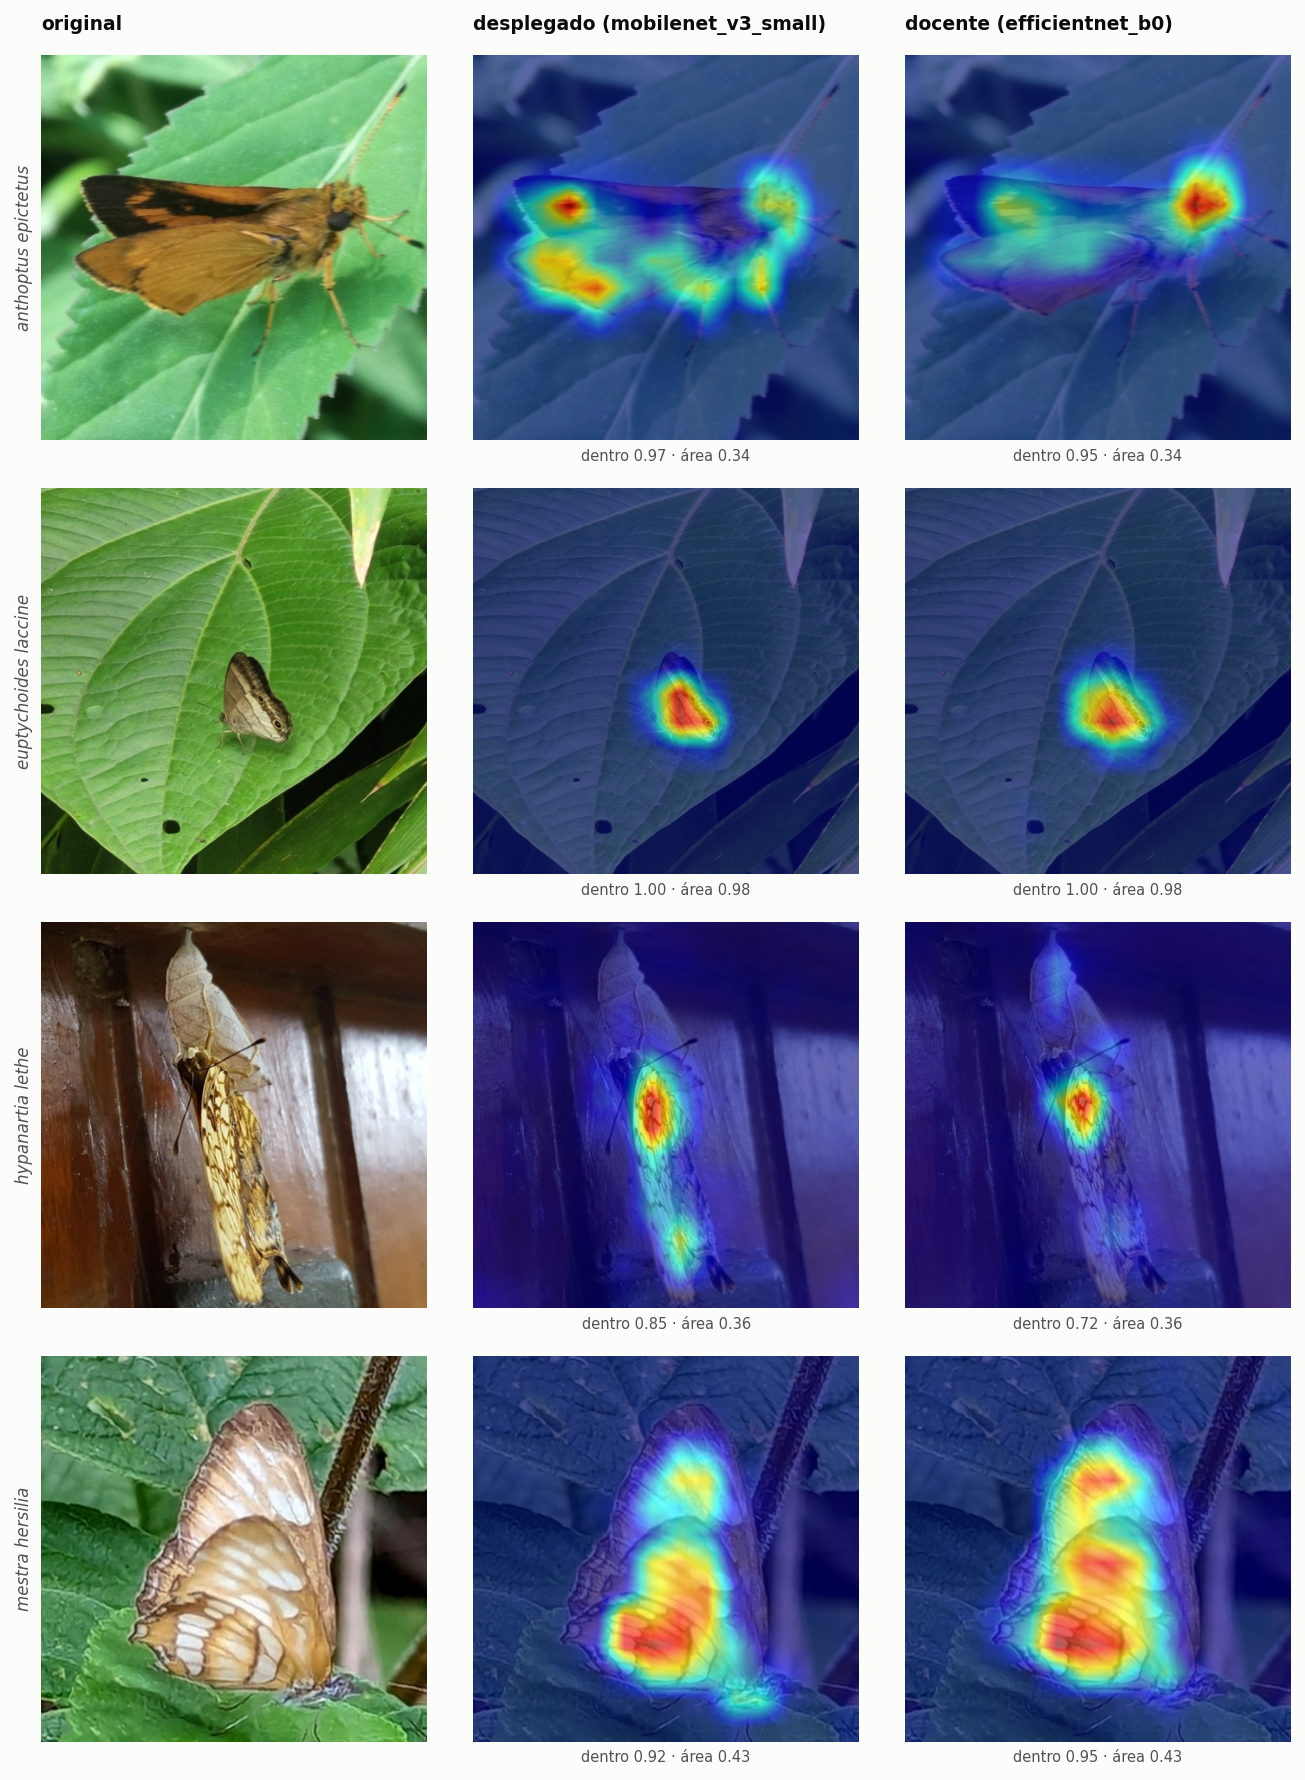

In [4]:
def rutaTest(archivo):
    especie = "_".join(archivo.split("_")[:-1])
    return Path("dataset/test") / especie / archivo


def predecir(m, img):
    arr = np.asarray(img.convert("RGB").resize(
        (m["modelo"].input_shape[2], m["modelo"].input_shape[1])), dtype=np.float32)
    probs = m["modelo"].predict(m["preprocess"](arr[None]), verbose=0)[0]
    return int(np.argmax(probs)), float(np.max(probs))


rng = np.random.default_rng(SEMILLA)
especiesPanel = sorted(rng.choice(clases, 4, replace=False))

filas = []
for especie in especiesPanel:
    candidatas = auditoria[auditoria.especie == especie]
    mejor = None
    for _, fila in candidatas.iterrows():
        img = Image.open(rutaTest(fila["archivo"]))
        idx, conf = predecir(MODELOS["desplegado"], img)
        if clases[idx] == especie and (mejor is None or conf > mejor[1]):
            mejor = (fila, conf, img, idx)
    if mejor is None:   # sin acierto: se muestra el error más confiado
        fila = candidatas.iloc[0]
        img = Image.open(rutaTest(fila["archivo"]))
        idx, conf = predecir(MODELOS["desplegado"], img)
        mejor = (fila, conf, img, idx)
    filas.append((especie, *mejor))

applyStyle()
fig, ejes = plt.subplots(len(filas), 3, figsize=(9, 3 * len(filas)))
for f, (especie, fila, conf, img, idx) in enumerate(filas):
    caja = cajaEnRecorte(fila)
    ejes[f, 0].imshow(img)
    limpiarEje(ejes[f, 0])
    ejes[f, 0].set_ylabel(especie.replace("_", " "), fontsize=8, style="italic")
    if f == 0:
        ejes[f, 0].set_title("original", fontsize=9)
    for k, rol in enumerate(("desplegado", "docente"), start=1):
        m = MODELOS[rol]
        mapa = computeGradcam(m["modelo"], img, idx, m["preprocess"])
        ejes[f, k].imshow(overlayHeatmap(img, mapa))
        limpiarEje(ejes[f, k])
        ejes[f, k].set_xlabel(f"dentro {fraccionDentro(mapa, caja):.2f} · área {areaCaja(caja):.2f}",
                              fontsize=7)
        if f == 0:
            ejes[f, k].set_title(f"{rol} ({m['arquitectura']})", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURAS / "panel_cualitativo.png", dpi=200, bbox_inches="tight")
plt.show()

## 3 · ¿Mira al ejemplar? La medición

Se calcula sobre una muestra del test. `dentro` es la fracción de activación
que cae en la caja; `area` es la misma fracción si la atención fuera uniforme.
La diferencia entre ambas es lo único que sostiene la afirmación "el modelo
mira la mariposa".

In [5]:
muestra = auditoria.sample(min(MUESTRA, len(auditoria)), random_state=SEMILLA)

registros = []
for _, fila in muestra.iterrows():
    img = Image.open(rutaTest(fila["archivo"]))
    caja = cajaEnRecorte(fila)
    area = areaCaja(caja)
    if area <= 0:
        continue
    for rol, m in MODELOS.items():
        idx, conf = predecir(m, img)
        mapa = computeGradcam(m["modelo"], img, idx, m["preprocess"])
        registros.append({
            "rol": rol,
            "especie": fila["especie"],
            "acierto": clases[idx] == fila["especie"],
            "confianza": conf,
            "dentro": fraccionDentro(mapa, caja),
            "area": area,
        })

atencion = pd.DataFrame(registros).dropna(subset=["dentro"])
atencion["exceso"] = atencion["dentro"] - atencion["area"]

resumen = atencion.groupby("rol").agg(
    n=("dentro", "size"),
    dentro_media=("dentro", "mean"),
    area_media=("area", "mean"),
    exceso_medio=("exceso", "mean"),
    exceso_mediano=("exceso", "median"),
).round(4)
print(resumen.to_string())
print()
for rol, g in atencion.groupby("rol"):
    frac = (g["exceso"] > 0).mean()
    print(f"  {rol:11} concentra por encima del azar en {frac:.1%} de las imágenes")

              n  dentro_media  area_media  exceso_medio  exceso_mediano
rol                                                                    
desplegado  150        0.9441      0.5092        0.4349          0.4567
docente     150        0.9399      0.5092        0.4307          0.4418

  desplegado  concentra por encima del azar en 98.7% de las imágenes
  docente     concentra por encima del azar en 98.7% de las imágenes


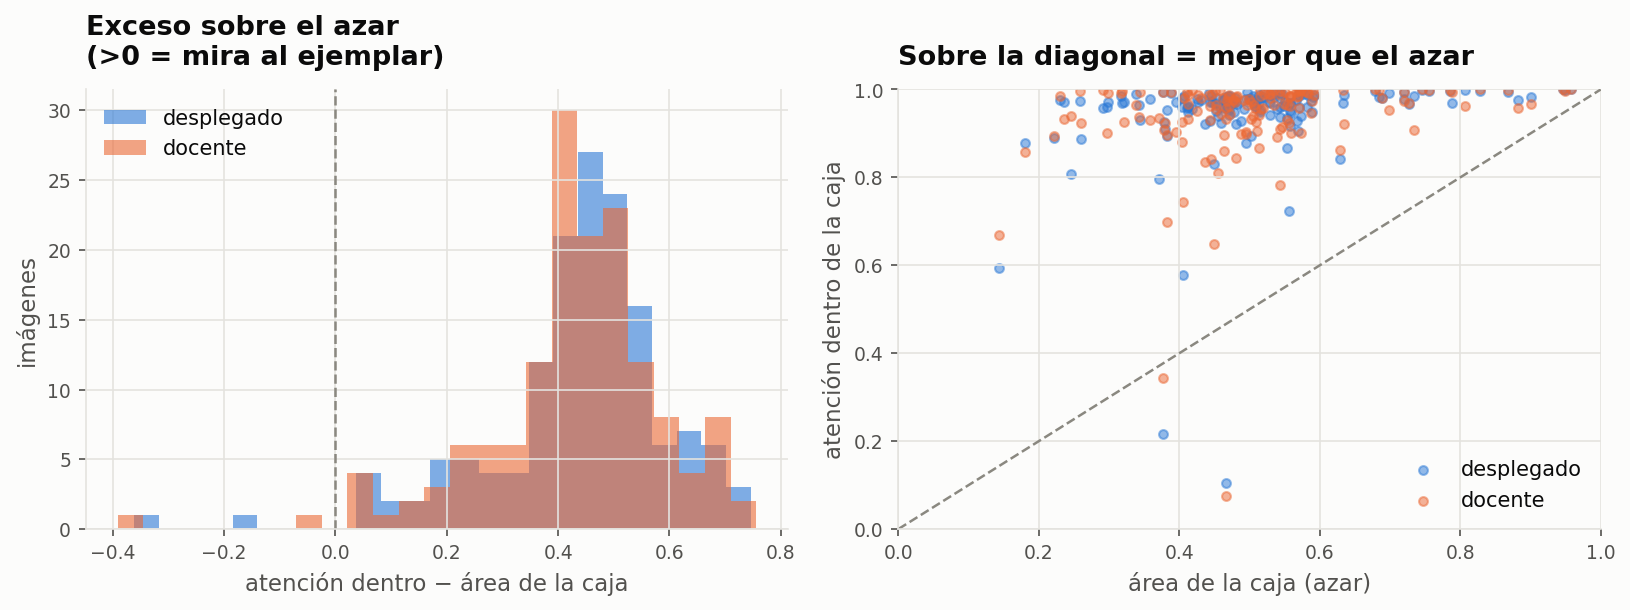

In [6]:
applyStyle()
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))

for rol, color in (("desplegado", SERIE_1), ("docente", SERIE_2)):
    g = atencion[atencion["rol"] == rol]
    ejes[0].hist(g["exceso"], bins=25, alpha=0.6, color=color, label=rol)
ejes[0].axvline(0, color=INK_MUTED, linestyle="--", linewidth=1.2)
ejes[0].set(xlabel="atención dentro − área de la caja", ylabel="imágenes",
            title="Exceso sobre el azar\n(>0 = mira al ejemplar)")
ejes[0].legend()

for rol, color in (("desplegado", SERIE_1), ("docente", SERIE_2)):
    g = atencion[atencion["rol"] == rol]
    ejes[1].scatter(g["area"], g["dentro"], s=18, alpha=0.5, color=color, label=rol)
lim = [0, 1]
ejes[1].plot(lim, lim, color=INK_MUTED, linestyle="--", linewidth=1.2)
ejes[1].set(xlim=lim, ylim=lim, xlabel="área de la caja (azar)",
            ylabel="atención dentro de la caja",
            title="Sobre la diagonal = mejor que el azar")
ejes[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig(FIGURAS / "atencion_vs_azar.png", dpi=200, bbox_inches="tight")
plt.show()

atencion.to_csv(FIGURAS / "atencion.csv", index=False)

## 4 · ¿Mira peor cuando se equivoca?

Si la atención cae fuera del ejemplar justo en los errores, Grad-CAM sirve como
señal de baja confiabilidad y no solo como ilustración.

In [7]:
porAcierto = atencion.groupby(["rol", "acierto"]).agg(
    n=("exceso", "size"),
    exceso_medio=("exceso", "mean"),
    confianza_media=("confianza", "mean"),
).round(4)
print(porAcierto.to_string())

print()
for rol, g in atencion.groupby("rol"):
    ok, mal = g[g["acierto"]]["exceso"], g[~g["acierto"]]["exceso"]
    if len(mal) >= 5:
        print(f"  {rol:11} exceso en aciertos {ok.mean():+.4f} vs errores {mal.mean():+.4f} "
              f"(diferencia {ok.mean() - mal.mean():+.4f}, n_errores={len(mal)})")
    else:
        print(f"  {rol:11} solo {len(mal)} errores en la muestra: insuficiente para comparar")

                      n  exceso_medio  confianza_media
rol        acierto                                    
desplegado False     13        0.3743           0.6314
           True     137        0.4407           0.9778
docente    False      8        0.2824           0.5975
           True     142        0.4391           0.9826

  desplegado  exceso en aciertos +0.4407 vs errores +0.3743 (diferencia +0.0663, n_errores=13)
  docente     exceso en aciertos +0.4391 vs errores +0.2824 (diferencia +0.1567, n_errores=8)


## 5 · Confusiones intra-género

Los pares congenéricos que más confunde el modelo desplegado, que son donde el mimetismo hace coincidir el patrón alar.

In [8]:
info = registro.readJson(registro.OUTPUTS_DIR / "desplegado.json")
metricas = registro.loadRunMetrics(info["run_id"])["splits"]["test"]
matriz = np.array(metricas["confusion_matrix"])
nombres = metricas["class_names"]

pares = [
    {"real": nombres[i], "predicha": nombres[j], "casos": int(matriz[i][j])}
    for i in range(len(nombres)) for j in range(len(nombres))
    if i != j and matriz[i][j] > 0 and nombres[i].split("_")[0] == nombres[j].split("_")[0]
]
pares = sorted(pares, key=lambda p: -p["casos"])[:3]
pd.DataFrame(pares)

,real,predicha,casos
0,parides_iphidamas,parides_eurimedes,9
1,parides_erithalion,parides_iphidamas,8
2,heraclides_thoas,heraclides_paeon,7


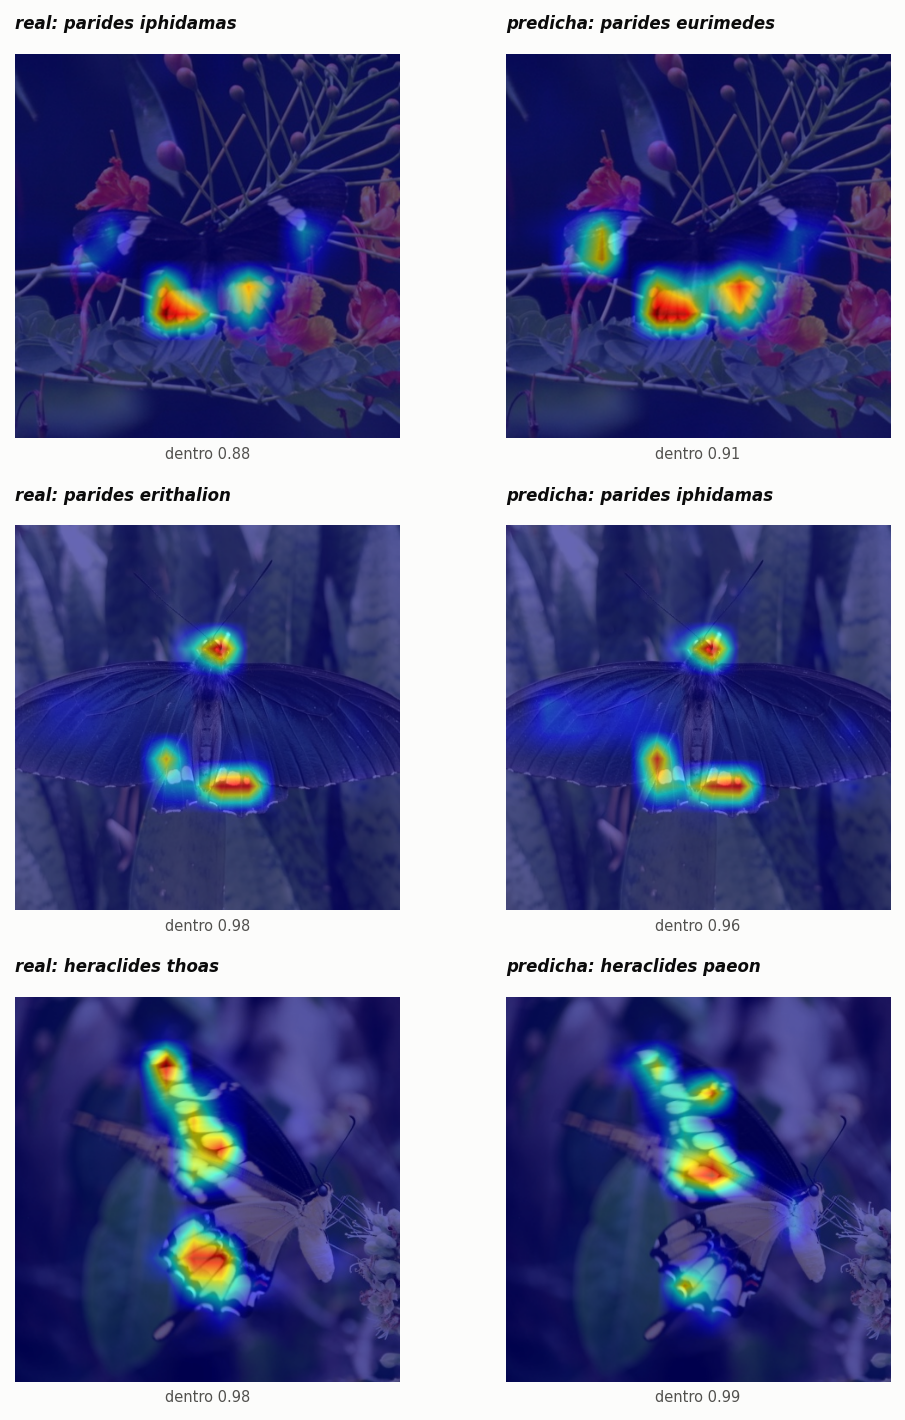

In [9]:
applyStyle()
m = MODELOS["desplegado"]
fig, ejes = plt.subplots(len(pares), 2, figsize=(7, 3.2 * len(pares)))
ejes = np.atleast_2d(ejes)

for f, par in enumerate(pares):
    fila = auditoria[auditoria.especie == par["real"]].iloc[0]
    img = Image.open(rutaTest(fila["archivo"]))
    caja = cajaEnRecorte(fila)
    for k, (etiqueta, especie) in enumerate((("real", par["real"]), ("predicha", par["predicha"]))):
        mapa = computeGradcam(m["modelo"], img, clases.index(especie), m["preprocess"])
        ejes[f, k].imshow(overlayHeatmap(img, mapa))
        limpiarEje(ejes[f, k])
        ejes[f, k].set_title(f"{etiqueta}: {especie.replace('_', ' ')}", fontsize=8, style="italic")
        ejes[f, k].set_xlabel(f"dentro {fraccionDentro(mapa, caja):.2f}", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURAS / "confusiones_genero.png", dpi=200, bbox_inches="tight")
plt.show()

## Lo que permite afirmar

Permite decir cuánta activación cae sobre el ejemplar frente a lo que daría el azar, medido sobre una muestra del test y no sobre una imagen elegida a mano. No permite decir que las regiones resaltadas sean los rasgos taxonómicos de un especialista: la caja acota al animal completo, no la venación ni los ocelos. Y la localización es gruesa por construcción, porque los mapas salen de la última capa convolucional, donde cada celda cubre 32 píxeles.